# Reinforcement Learning: Tabular RL from Scratch

> **Who is this for:** you have read the RL theory notebooks [`01`](01_rl_fundamentals.ipynb)–[`03`](03_monte_carlo_td.ipynb) and [`07`](07_multi_armed_bandits.ipynb) (MDPs, Bellman equations, bandits) and now want to **build and run every classic tabular algorithm yourself**. It is also for BS/MS students revising for an RL exam, because every algorithm here appears in Sutton & Barto, chapters 3–8 and 12.
>
> **What you will learn:**
> - How to write a **GridWorld environment** with a Gymnasium-style API (`reset`, `step`, `terminated`, `truncated`) and a full transition model `P[s][a]`, including a stochastic "slip"
> - **Policy evaluation, policy iteration and value iteration** from scratch, checked against the textbook numbers of the AIMA 4×3 world and against an exact linear solve; convergence plots and the effect of the discount γ
> - **Monte Carlo** prediction and control (first-visit, ε-soft), and **importance sampling** (ordinary vs weighted) for off-policy learning
> - **TD(0), SARSA, Expected SARSA and Q-learning**, run on Gymnasium's `CliffWalking-v1`, including the famous "safe path vs optimal path" result
> - **n-step TD** and **TD(λ) with eligibility traces** on the random-walk benchmark
> - **Exploration** strategies (ε-decay, optimistic initial values, a UCB-style bonus), with learning curves over many seeds and 95% confidence bands
> - **Dyna-Q**: how a learned model makes an agent far more sample-efficient
> - A **reward-shaping pitfall** (an agent that farms a bonus in a loop) and the fix, **potential-based shaping**
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb), [NumPy](../02_Data_Analysis/02_numpy.ipynb), [RL fundamentals](01_rl_fundamentals.ipynb), [dynamic programming theory](02_dynamic_programming.ipynb), [MC and TD theory](03_monte_carlo_td.ipynb). Basic probability (expected value) from [`14_Mathematics/03_probability`](../14_Mathematics/03_probability.ipynb).
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet. NumPy, pandas, matplotlib and `gymnasium` (installed with the repo requirements). The whole notebook runs in about two minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

Reinforcement learning (RL) is learning by **trial and error with a score**. An agent (a robot, a game player, a program) tries an action, the world reacts, and the agent gets points or loses points. Over many tries it learns which actions lead to the most points in the long run, not just right now. "Tabular" means the world is small enough that we can keep a table with one row per situation, like a notebook in which a new taxi driver writes "from this junction, turning left was usually good".

Two everyday examples. A child learning to ride a bike gets no instructions for each muscle, only feedback (wobbling, falling, going straight), and slowly learns what works. A dog learning tricks gets a treat after the right behaviour, and learns to repeat what earned treats, even when the treat comes a few seconds later. That "a few seconds later" is the hard part: RL has to work out which earlier action deserves the credit.

**Tiny example.** You are one step from the exit of a maze. Moving right reaches the exit (+10 points). Moving left costs 1 point and leaves you two steps from the exit. If future points count 90% as much as points now (discount γ = 0.9), going right is worth 10, while going left is worth about −1 + 0.9 × 0.9 × 10 ≈ 7.1. A table of these numbers ("values") tells the agent what to do in every square.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Value function | "How good is it to be here, counting all future rewards?" | game AIs scoring board positions, AlphaZero's value head |
| Q-learning / SARSA | learn a score for every (situation, action) pair from experience | robot navigation, game bots, the ancestor of DQN |
| Model-based planning (Dyna) | imagine experience with a learned model of the world | MuZero, world models, LLM agents that plan before acting |

### How this notebook is different from `01`–`03`
Notebooks [`01`](01_rl_fundamentals.ipynb), [`02`](02_dynamic_programming.ipynb) and [`03`](03_monte_carlo_td.ipynb) give the formulas with a short demo each. Here every algorithm is **implemented, run, plotted and checked** (against textbook numbers, an exact linear solve or another algorithm). The deep-RL sequel is [`10_deep_rl_on_cpu`](10_deep_rl_on_cpu.ipynb).

## Table of contents
1. A GridWorld environment with a Gymnasium-style API
2. Dynamic programming: policy evaluation, policy iteration, value iteration, the effect of γ
3. Monte Carlo methods and importance sampling
4. Temporal-difference learning: TD(0), SARSA, Expected SARSA, Q-learning on CliffWalking
5. n-step TD and TD(λ) with eligibility traces
6. Exploration strategies and learning curves over seeds
7. Dyna-Q: model-based planning
8. Reward shaping: a pitfall and the safe fix
9. Summary table
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import math, time, random, sys
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

SEED = 42
random.seed(SEED); np.random.seed(SEED)          # reproducible randomness

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})
pd.set_option("display.width", 140)
NOTEBOOK_START = time.time()
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| gymnasium", gym.__version__)

Python 3.12.3 | numpy 2.4.6 | gymnasium 1.4.0


## 1. A GridWorld environment with a Gymnasium-style API

> 💬 **In plain English:** we build a tiny world (a grid with a goal and a pit) that an agent can move around in, with the same buttons (reset, step) as professional RL libraries.

A **Markov decision process (MDP)** is a tuple $(\mathcal S, \mathcal A, P, R, \gamma)$: states, actions, transition probabilities $P(s' \mid s, a)$, rewards and a discount factor $\gamma \in [0, 1]$. The agent picks actions with a **policy** $\pi(a \mid s)$ and wants to maximise the expected **return** $G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \dots$

We build the classic **4×3 world** from Russell & Norvig (AIMA, ch. 17):

```
 row 0:  .  .  .  G(+1)
 row 1:  .  #  .  P(-1)        # = wall,  G = goal (+1),  P = pit (-1)
 row 2:  S  .  .  .            S = start
```

- Every move costs **−0.04** (so wandering is discouraged).
- Moves are **stochastic**: the intended direction happens with probability 0.8; with probability 0.1 each the agent slips 90° left or right. Bumping into a wall or the edge means staying put.
- `G` and `P` are **terminal**: the episode ends there.

Our class follows the Gymnasium conventions, so the same agent code also works on real Gymnasium environments later:

| Method / attribute | Meaning |
|---|---|
| `reset(seed)` → `(state, info)` | start a new episode |
| `step(a)` → `(state, reward, terminated, truncated, info)` | `terminated` = reached a terminal state; `truncated` = hit the time limit |
| `P[s][a]` → list of `(prob, next_state, reward, done)` | the full model (Gymnasium's toy-text envs expose the same `P`); only DP and Dyna are allowed to look at it |

In [2]:
ACTIONS = {0: (-1, 0), 1: (0, 1), 2: (1, 0), 3: (0, -1)}   # up, right, down, left as (row change, col change)
ARROWS = {0: "↑", 1: "→", 2: "↓", 3: "←"}

class GridWorld:
    """A small grid MDP. Layout characters: '.' free, '#' wall, 'S' start, 'G' goal, 'P' pit, 'C' checkpoint (plain cell)."""
    def __init__(self, layout, slip=0.2, step_reward=-0.04, goal_reward=1.0, pit_reward=-1.0, max_steps=200):
        self.layout = layout
        self.grid = [list(row) for row in layout]
        self.n_rows, self.n_cols = len(self.grid), len(self.grid[0])
        self.slip, self.step_reward, self.max_steps = slip, step_reward, max_steps
        self.bonus = {"G": goal_reward, "P": pit_reward}                  # extra reward for ENTERING these cells
        self.cells = [(r, c) for r in range(self.n_rows) for c in range(self.n_cols) if self.grid[r][c] != "#"]
        self.index = {rc: i for i, rc in enumerate(self.cells)}          # (row, col) -> state number
        self.n_states, self.n_actions = len(self.cells), 4
        self.start = self.index[next(rc for rc in self.cells if self.grid[rc[0]][rc[1]] == "S")]
        self.terminal = {self.index[rc] for rc in self.cells if self.grid[rc[0]][rc[1]] in "GP"}
        self.P = self._build_model()                                      # P[s][a] = [(prob, s2, r, done), ...]
        self.rng = np.random.default_rng(0)

    def _move(self, rc, a):                       # deterministic effect of action a from cell rc
        r, c = rc[0] + ACTIONS[a][0], rc[1] + ACTIONS[a][1]
        if 0 <= r < self.n_rows and 0 <= c < self.n_cols and self.grid[r][c] != "#":
            return (r, c)
        return rc                                 # bumped into a wall or the edge: stay put

    def _build_model(self):
        P = {}
        for s, rc in enumerate(self.cells):
            P[s] = {}
            for a in range(4):
                if s in self.terminal:            # terminal states are absorbing with zero reward
                    P[s][a] = [(1.0, s, 0.0, True)]
                    continue
                outcomes = defaultdict(float)
                for prob, actual in [(1 - self.slip, a), (self.slip / 2, (a + 1) % 4), (self.slip / 2, (a + 3) % 4)]:
                    if prob > 0:
                        outcomes[self.index[self._move(rc, actual)]] += prob   # merge identical outcomes
                P[s][a] = []
                for s2, prob in outcomes.items():
                    cell = self.grid[self.cells[s2][0]][self.cells[s2][1]]
                    P[s][a].append((prob, s2, self.step_reward + self.bonus.get(cell, 0.0), s2 in self.terminal))
        return P

    def reset(self, seed=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        self.s, self.t = self.start, 0
        return self.s, {}

    def step(self, a):
        u, acc = self.rng.random(), 0.0               # sample one outcome: walk along the cumulative probabilities
        for prob, s2, r, terminated in self.P[self.s][a]:
            acc += prob
            if u < acc:
                break
        self.s, self.t = s2, self.t + 1
        truncated = (self.t >= self.max_steps) and not terminated
        return s2, r, terminated, truncated, {}

AIMA_LAYOUT = ["...G",
               ".#.P",
               "S..."]
env = GridWorld(AIMA_LAYOUT)
print("states:", env.n_states, "| actions:", env.n_actions, "| start:", env.start, "| terminal:", sorted(env.terminal))
print("P[start][up] =", env.P[env.start][0])
for s in env.P:                                           # sanity check: every row of P sums to 1
    for a in env.P[s]:
        assert abs(sum(p for p, *_ in env.P[s][a]) - 1) < 1e-12

states: 11 | actions: 4 | start: 7 | terminal: [3, 6]
P[start][up] = [(0.8, 4, -0.04, False), (0.1, 8, -0.04, False), (0.1, 7, -0.04, False)]


**What just happened?** From the start (bottom-left) "up" succeeds with probability 0.8, slips right with 0.1, and slips left with 0.1. Slipping left hits the edge, so the agent stays put. All three outcomes cost −0.04. Every probability row sums to 1 (we asserted it).

Now a plotting helper that draws values as a heatmap with the policy as arrows, and a random rollout to see the API in action.

In [3]:
def plot_values(env, V, policy=None, title="", ax=None, fmt="{:.2f}", cmap="RdYlGn"):
    """Heatmap of state values V (one per state) with optional greedy-policy arrows."""
    grid = np.full((env.n_rows, env.n_cols), np.nan)
    inner = [V[s] for s in range(env.n_states) if s not in env.terminal]
    for s, (r, c) in enumerate(env.cells):
        ch = env.grid[r][c]
        grid[r, c] = max(inner) if ch == "G" else min(inner) if ch == "P" else V[s]   # colour G green, P red
    ax = ax or plt.subplots(figsize=(1.1 * env.n_cols + 1, 1.1 * env.n_rows))[1]
    ax.imshow(grid, cmap=cmap, vmin=np.nanmin(grid), vmax=np.nanmax(grid))
    for s, (r, c) in enumerate(env.cells):
        ch = env.grid[r][c]
        label = ch if ch in "GP" else fmt.format(V[s])
        if policy is not None and s not in env.terminal:
            label = ARROWS[int(policy[s])] + "\n" + label
        ax.text(c, r, label, ha="center", va="center", fontsize=9)
    for r in range(env.n_rows):                       # draw walls in grey
        for c in range(env.n_cols):
            if env.grid[r][c] == "#":
                ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color="#777777"))
    ax.set_xticks(range(env.n_cols)); ax.set_yticks(range(env.n_rows)); ax.grid(False)
    ax.set_xlabel("column"); ax.set_ylabel("row"); ax.set_title(title)
    return ax

def rollout(env, policy_fn, seed=0):
    """Run one episode; policy_fn(state) -> action. Returns the list of (s, a, r) and the return."""
    s, _ = env.reset(seed=seed)
    traj, done = [], False
    while not done:
        a = policy_fn(s)
        s2, r, terminated, truncated, _ = env.step(a)
        traj.append((s, a, r)); s = s2
        done = terminated or truncated
    return traj, sum(r for *_, r in traj)

rng = np.random.default_rng(0)
traj, G = rollout(env, lambda s: int(rng.integers(4)), seed=0)
print(f"Random policy: {len(traj)} steps, return {G:+.2f}, ended in", env.cells[env.s], env.grid[env.cells[env.s][0]][env.cells[env.s][1]])
returns = [rollout(env, lambda s: int(rng.integers(4)), seed=i)[1] for i in range(1000)]
print(f"Average return of the random policy over 1000 episodes: {np.mean(returns):+.3f}")

Random policy: 88 steps, return -4.52, ended in (1, 3) P


Average return of the random policy over 1000 episodes: -1.609


## 2. Dynamic programming (the model is known)

> 💬 **In plain English:** if we know exactly how the world works, we can compute how good every square is by repeatedly asking 'what is the best I can get from here?'.

**Dynamic programming (DP)** in RL means computing value functions **exactly from the model** $P$, by repeatedly applying the Bellman equations. No trial and error is needed, but we must know $P$, which is rarely true in practice. DP is still the reference that every learning method approximates.

The **state-value function** of a policy is $v_\pi(s) = \mathbb E_\pi[G_t \mid S_t = s]$, and it satisfies the **Bellman expectation equation**

$$v_\pi(s) = \sum_a \pi(a\mid s) \sum_{s'} P(s'\mid s,a)\,\big[r(s,a,s') + \gamma\, v_\pi(s')\big].$$

### 2.1 Iterative policy evaluation
Start with $V = 0$ and sweep over all states, replacing $V(s)$ by the right-hand side, until the largest change $\Delta$ is below a threshold θ. Because the Bellman operator is a **γ-contraction** (for γ < 1), the error shrinks by at least a factor γ each sweep.

For a fixed policy the equation is **linear**, so we can also solve it exactly: $v_\pi = (I - \gamma P_\pi)^{-1} r_\pi$. We use that to check our loop.

Iterative evaluation of the random policy took 408 sweeps; max difference from the exact linear solve = 2.5e-07
v_random(start) = -1.587  (compare with the Monte Carlo average of the random rollouts above)


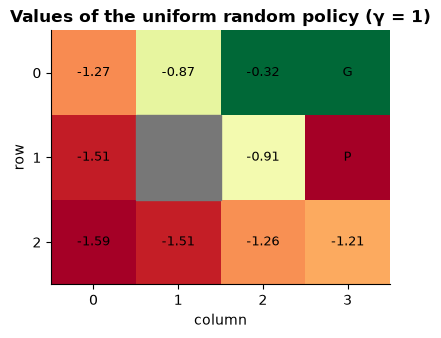

In [4]:
def q_from_v(env, V, s, gamma):
    """One-step look-ahead: Q(s, a) for all actions, given state values V."""
    return np.array([sum(p * (r + gamma * V[s2] * (not done)) for p, s2, r, done in env.P[s][a])
                     for a in range(env.n_actions)])

def policy_evaluation(env, pi, gamma=1.0, theta=1e-8, max_sweeps=10_000):
    """pi is an (n_states, n_actions) array of action probabilities. Returns V and the max change per sweep."""
    V, deltas = np.zeros(env.n_states), []
    for _ in range(max_sweeps):
        V_new = np.array([pi[s] @ q_from_v(env, V, s, gamma) for s in range(env.n_states)])   # synchronous sweep
        deltas.append(np.abs(V_new - V).max()); V = V_new
        if deltas[-1] < theta:
            break
    return V, deltas

def exact_policy_value(env, pi, gamma=1.0):
    """Solve the linear Bellman system (I - gamma P_pi) v = r_pi directly (terminal states have value 0)."""
    n = env.n_states
    P_pi, r_pi = np.zeros((n, n)), np.zeros(n)
    for s in range(n):
        if s in env.terminal:
            continue                                  # row stays zero -> v(terminal) = 0
        for a in range(env.n_actions):
            for p, s2, r, done in env.P[s][a]:
                r_pi[s] += pi[s, a] * p * r
                if not done:
                    P_pi[s, s2] += pi[s, a] * p
    return np.linalg.solve(np.eye(n) - gamma * P_pi, r_pi)

uniform = np.full((env.n_states, env.n_actions), 0.25)          # the random policy
V_rand, deltas_rand = policy_evaluation(env, uniform, gamma=1.0)
V_exact = exact_policy_value(env, uniform, gamma=1.0)
assert np.allclose(V_rand, V_exact, atol=1e-6)
print(f"Iterative evaluation of the random policy took {len(deltas_rand)} sweeps; "
      f"max difference from the exact linear solve = {np.abs(V_rand - V_exact).max():.1e}")
print(f"v_random(start) = {V_rand[env.start]:+.3f}  (compare with the Monte Carlo average of the random rollouts above)")
plot_values(env, V_rand, title="Values of the uniform random policy (γ = 1)"); plt.show()

**What just happened?** The iterative sweeps and the exact linear solve agree to within $10^{-6}$. The random policy is poor: from the start its value is negative, and the value near the pit is strongly negative because random moves often fall in. The Monte Carlo average over 1000 random episodes (section 1) should be close to $v_{\text{random}}(\text{start})$, since a value *is* an expected return.

### 2.2 Policy iteration
**Policy improvement theorem:** if we act greedily with respect to $v_\pi$, the new policy $\pi'$ satisfies $v_{\pi'} \ge v_\pi$ everywhere. **Policy iteration** alternates *evaluate* → *improve greedily* until the policy stops changing. For a finite MDP it terminates in a finite number of iterations (there are only $|\mathcal A|^{|\mathcal S|}$ deterministic policies), usually very few.

In [5]:
def greedy_policy(env, V, gamma):
    """Deterministic greedy policy as an array of actions (ties broken by the lowest action index)."""
    return np.array([int(np.argmax(q_from_v(env, V, s, gamma))) for s in range(env.n_states)])

def one_hot(actions, n_actions=4):
    pi = np.zeros((len(actions), n_actions)); pi[np.arange(len(actions)), actions] = 1.0
    return pi

def policy_iteration(env, gamma=1.0, theta=1e-10):
    actions = np.zeros(env.n_states, dtype=int)              # start with "always go up"
    history = []
    while True:
        V, sweeps = policy_evaluation(env, one_hot(actions), gamma, theta)
        new_actions = greedy_policy(env, V, gamma)
        changed = int(np.sum(new_actions != actions))
        history.append({"iteration": len(history) + 1, "eval sweeps": len(sweeps), "V(start)": V[env.start], "actions changed": changed})
        if changed == 0:
            return V, actions, pd.DataFrame(history)
        actions = new_actions

V_pi, policy_pi, pi_trace = policy_iteration(env, gamma=1.0)
print(pi_trace.round(4).to_string(index=False))

 iteration  eval sweeps  V(start)  actions changed
         1          969   -1.4662                6
         2           37    0.5082                1
         3           36    0.6910                1
         4           38    0.7053                1
         5           40    0.7053                0


**What just happened?** Each row is one evaluate-then-improve cycle. The policy stops changing after only a handful of iterations, even though there are $4^{11} \approx 4$ million deterministic policies. The value of the start state rises at every iteration, as the policy improvement theorem promises.

### 2.3 Value iteration
**Value iteration** skips the full evaluation and applies the **Bellman optimality** update directly:

$$V_{k+1}(s) = \max_a \sum_{s'} P(s'\mid s,a)\big[r + \gamma V_k(s')\big].$$

It converges to the optimal value $v_*$; the greedy policy with respect to $v_*$ is optimal. The AIMA textbook (Fig. 17.3, 4th ed.) prints the utilities for this exact world with γ = 1, so we can check our code against the book.

Value iteration: 40 sweeps. All 9 AIMA utilities match the book; VI and PI give the same values and policy.


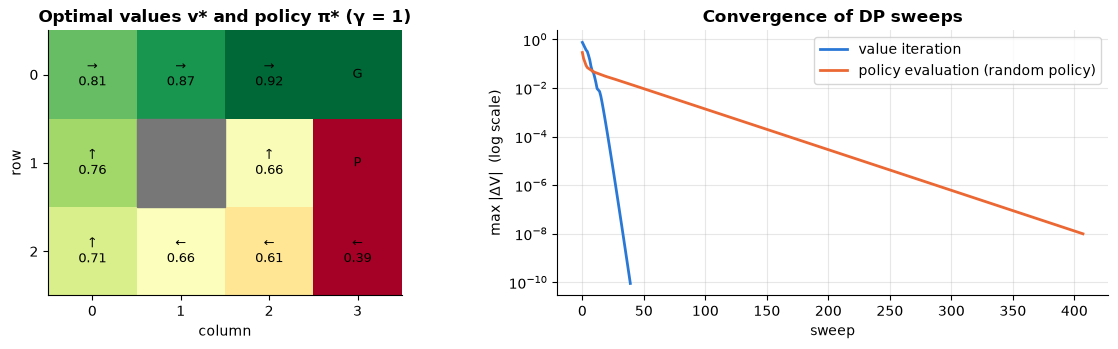

In [6]:
def value_iteration(env, gamma=1.0, theta=1e-10, max_sweeps=10_000):
    V, deltas = np.zeros(env.n_states), []
    for _ in range(max_sweeps):
        V_new = np.array([q_from_v(env, V, s, gamma).max() if s not in env.terminal else 0.0
                          for s in range(env.n_states)])
        deltas.append(np.abs(V_new - V).max()); V = V_new
        if deltas[-1] < theta:
            break
    return V, greedy_policy(env, V, gamma), deltas

V_star, policy_star, deltas_vi = value_iteration(env, gamma=1.0)

AIMA_BOOK = {(0, 0): 0.812, (0, 1): 0.868, (0, 2): 0.918,          # utilities printed in AIMA (rounded to 3 dp)
             (1, 0): 0.762, (1, 2): 0.660,
             (2, 0): 0.705, (2, 1): 0.655, (2, 2): 0.611, (2, 3): 0.388}
for rc, book in AIMA_BOOK.items():
    assert abs(V_star[env.index[rc]] - book) < 5e-4, (rc, V_star[env.index[rc]], book)
assert np.allclose(V_star, V_pi, atol=1e-6) and np.array_equal(policy_star, policy_pi)
print(f"Value iteration: {len(deltas_vi)} sweeps. All 9 AIMA utilities match the book; VI and PI give the same values and policy.")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_values(env, V_star, policy_star, title="Optimal values v* and policy π* (γ = 1)", ax=axes[0])
axes[1].semilogy(deltas_vi, label="value iteration")
axes[1].semilogy(deltas_rand, label="policy evaluation (random policy)")
axes[1].set_xlabel("sweep"); axes[1].set_ylabel("max |ΔV|  (log scale)"); axes[1].set_title("Convergence of DP sweeps"); axes[1].legend()
plt.tight_layout(); plt.show()

**What just happened?** Our values equal the textbook's to three decimals (for example 0.705 at the start and 0.388 next to the pit). Look at the policy in the bottom row at (row 2, col 2): the optimal action is **←**, *away* from the goal. The short route goes up through (1, 2), right next to the pit, where every "up" move has a 10% chance of slipping right into it. With a step cost of only −0.04 it is worth taking the long, safe way round the wall instead. The convergence plot is a straight line on a log scale: the error shrinks geometrically, which is the contraction property in action.

### 2.4 The effect of the discount γ
γ says how much the future counts. Small γ means a short-sighted agent. In theory value iteration needs about $\log(1/\theta)/\log(1/\gamma)$ sweeps to reach accuracy θ, so the closer γ is to 1, the slower it converges.

 gamma  sweeps to θ=1e-8  V*(start) action at (1,2) action at (2,2)  same policy as γ=1
  0.50                20     -0.045               ↑               ↑               False
  0.80                23      0.151               ↑               ↑               False
  0.90                26      0.351               ↑               ↑               False
  0.99                32      0.660               ↑               ↑               False
  1.00                34      0.705               ↑               ←                True


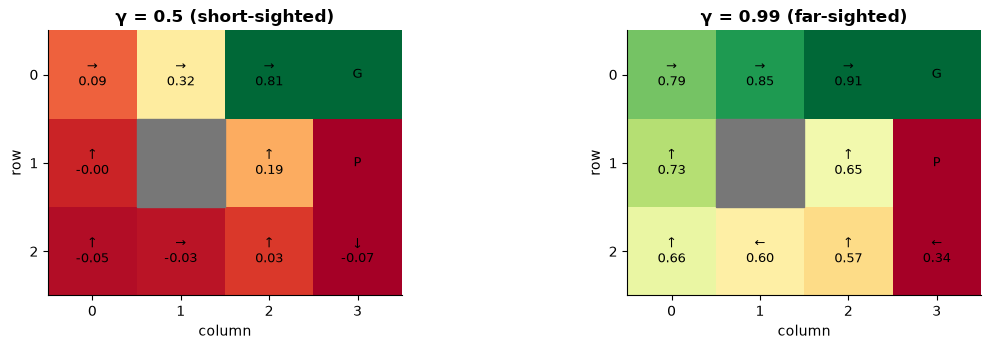

In [7]:
rows, policies = [], {}
for gamma in [0.5, 0.8, 0.9, 0.99, 1.0]:
    V_g, pol_g, d_g = value_iteration(env, gamma=gamma, theta=1e-8)
    policies[gamma] = (V_g, pol_g)
    rows.append({"gamma": gamma, "sweeps to θ=1e-8": len(d_g), "V*(start)": round(V_g[env.start], 3),
                 "action at (1,2)": ARROWS[int(pol_g[env.index[(1, 2)]])],
                 "action at (2,2)": ARROWS[int(pol_g[env.index[(2, 2)]])],
                 "same policy as γ=1": bool(np.array_equal(pol_g, policy_star))})
gamma_table = pd.DataFrame(rows)
print(gamma_table.to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_values(env, *policies[0.5], title="γ = 0.5 (short-sighted)", ax=axes[0])
plot_values(env, *policies[0.99], title="γ = 0.99 (far-sighted)", ax=axes[1])
plt.tight_layout(); plt.show()

**What just happened?** As γ grows, value iteration needs more sweeps, as the theory predicts. With γ = 0.5 a reward two or more steps away is worth very little, so values far from the goal are close to zero (the start is even slightly negative). The policies differ in exactly one cell, (2, 2): for **every γ < 1 in the table** the agent takes the short, risky route **↑** past the pit, and only with γ = 1 does it take the long safe detour **←**. Discounting makes the four extra steps of the detour expensive, so a discounting agent accepts a 10% slip risk to get the +1 sooner. γ is not just a convergence trick: it changes what "optimal" means.

**Complexity.** One sweep of policy evaluation or value iteration costs $O(|\mathcal S|^2|\mathcal A|)$ in general (or $O(|\mathcal S||\mathcal A| b)$ with $b$ successors per action; here $b \le 3$). Policy iteration needs few outer iterations but each contains a full evaluation (or one $O(|\mathcal S|^3)$ linear solve).

> ⚠️ **Common mistake:** forgetting to set the value of terminal states to 0 (or bootstrapping from them). If $V(\text{terminal})$ drifts, every value next to it is wrong. In code this is the `* (not done)` factor.

> 🎓 **Exam / interview tip:** "Policy iteration vs value iteration?" PI does few, expensive iterations (full evaluation each time) and stops exactly when the policy is stable. VI does many cheap sweeps and stops when values change less than θ. Both are special cases of **generalised policy iteration (GPI)**.

## 3. Monte Carlo methods (learn from complete episodes)

> 💬 **In plain English:** without knowing the rules, play many complete games and average the scores you actually got from each square.

Monte Carlo (MC) methods estimate a value by **averaging the returns actually observed** after visiting a state. No model is needed, only complete episodes.

- **First-visit MC prediction:** for each episode, for the *first* time step $t$ at which $s$ is visited, append $G_t$ to `returns[s]`; $V(s)$ is the average. It is unbiased, and by the law of large numbers converges to $v_\pi(s)$.
- **Every-visit MC** uses all visits; it is biased for finite samples but also consistent.

We evaluate the optimal policy π* from section 2 and compare with its exact value.

States visited by π*: 7 of 11.  RMS error after 2000 episodes: 0.0063
V_MC(start) = 0.703 vs exact 0.705


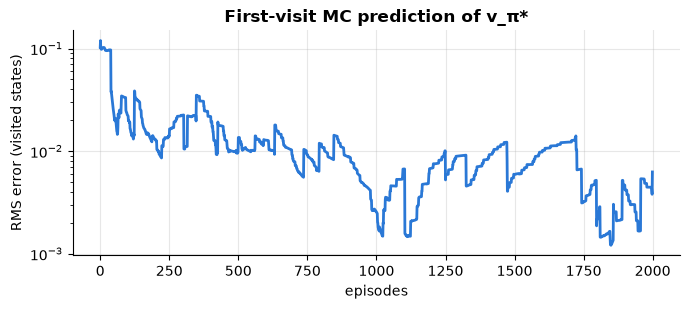

In [8]:
def episode_returns(traj, gamma):
    """Given [(s, a, r), ...], return the list of returns G_t for every time step (computed backwards)."""
    G, out = 0.0, []
    for s, a, r in reversed(traj):
        G = r + gamma * G
        out.append(G)
    return out[::-1]

def mc_prediction_first_visit(env, policy_fn, n_episodes, gamma=1.0, seed=0, truth=None):
    returns_sum, returns_cnt = np.zeros(env.n_states), np.zeros(env.n_states)
    rms = []
    for ep in range(n_episodes):
        traj, _ = rollout(env, policy_fn, seed=seed if ep == 0 else None)
        Gs = episode_returns(traj, gamma)
        seen = set()
        for t, (s, a, r) in enumerate(traj):
            if s not in seen:                         # first visit only
                seen.add(s)
                returns_sum[s] += Gs[t]; returns_cnt[s] += 1
        V = np.divide(returns_sum, returns_cnt, out=np.zeros(env.n_states), where=returns_cnt > 0)
        if truth is not None:
            visited = returns_cnt > 0
            rms.append(np.sqrt(np.mean((V[visited] - truth[visited]) ** 2)))
    return V, returns_cnt, rms

V_true_star = exact_policy_value(env, one_hot(policy_star), gamma=1.0)
V_mc, counts, rms_mc = mc_prediction_first_visit(env, lambda s: int(policy_star[s]), 2000, truth=V_true_star)
visited = counts > 0
print(f"States visited by π*: {visited.sum()} of {env.n_states}.  RMS error after 2000 episodes: {rms_mc[-1]:.4f}")
print(f"V_MC(start) = {V_mc[env.start]:.3f} vs exact {V_true_star[env.start]:.3f}")
plt.figure(figsize=(7, 3.2)); plt.plot(rms_mc); plt.yscale("log")
plt.xlabel("episodes"); plt.ylabel("RMS error (visited states)"); plt.title("First-visit MC prediction of v_π*")
plt.tight_layout(); plt.show()

**What just happened?** The MC estimate approaches the exact value, and the error falls roughly like $1/\sqrt{n}$ (a straight line with slope −½ on log–log axes): standard Monte Carlo behaviour. Notice that π* never visits some states, so MC learns **nothing** about them. That is why control needs exploration.

### 3.1 On-policy MC control with ε-soft policies
To improve a policy without a model we need **action values** $Q(s, a)$, and every pair must keep being tried. An **ε-soft** policy gives every action probability at least $\varepsilon/|\mathcal A|$. **On-policy first-visit MC control**: generate an episode with the ε-greedy policy, update $Q$ toward the observed returns, repeat. It converges to the best ε-soft policy.

In [9]:
def epsilon_greedy(Q_row, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(len(Q_row)))
    best = np.flatnonzero(Q_row == Q_row.max())     # break ties at random (important early on, when Q is all zeros)
    return int(best[rng.integers(len(best))])

def mc_control_epsilon_soft(env, n_episodes=4000, eps=0.1, gamma=1.0, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions)); N = np.zeros_like(Q)
    for ep in range(n_episodes):
        traj, _ = rollout(env, lambda s: epsilon_greedy(Q[s], eps, rng), seed=seed if ep == 0 else None)
        Gs = episode_returns(traj, gamma)
        seen = set()
        for t, (s, a, r) in enumerate(traj):
            if (s, a) not in seen:
                seen.add((s, a))
                N[s, a] += 1
                Q[s, a] += (Gs[t] - Q[s, a]) / N[s, a]   # incremental average of returns
    return Q

Q_mc = mc_control_epsilon_soft(env)
greedy_mc = Q_mc.argmax(1)
non_terminal = [s for s in range(env.n_states) if s not in env.terminal]
agree = np.mean(greedy_mc[non_terminal] == policy_star[non_terminal])
V_greedy_mc = exact_policy_value(env, one_hot(greedy_mc))
print(f"Greedy policy from MC control agrees with π* in {agree:.0%} of non-terminal states")
print(f"Exact value at start: greedy-MC policy {V_greedy_mc[env.start]:.3f} vs optimal {V_star[env.start]:.3f}")

Greedy policy from MC control agrees with π* in 78% of non-terminal states
Exact value at start: greedy-MC policy 0.691 vs optimal 0.705


**What just happened?** Without ever looking at $P$, MC control found a policy that agrees with π* in most states. Where it differs, the exact value at the start state tells us how much it costs. MC needs many episodes because each update waits for the end of an episode and returns are noisy.

### 3.2 Off-policy prediction with importance sampling
**Off-policy** learning evaluates a **target policy** π using data from a different **behaviour policy** $b$ (for example, logged data). Returns are reweighted by the **importance-sampling ratio**

$$\rho_{t:T-1} = \prod_{k=t}^{T-1} \frac{\pi(A_k\mid S_k)}{b(A_k\mid S_k)}.$$

- **Ordinary IS**: $V(s) = \frac{\sum \rho\,G}{n}$: unbiased, but the variance can be huge (even infinite).
- **Weighted IS**: $V(s) = \frac{\sum \rho\,G}{\sum \rho}$: biased (the bias vanishes as $n\to\infty$), much lower variance; preferred in practice.

Here the target is the deterministic π* and the behaviour policy is an exploratory version of it: with probability 0.7 it takes π*'s action and otherwise one of the other three (0.1 each). So ρ is either 0 (the episode deviated from π* at some step) or $(1/0.7)^{T}$ (it followed π* for all $T$ steps).

After 1000 episodes (100 runs): ordinary IS mean 0.693 ± 0.074 | weighted IS mean 0.710 ± 0.035 | truth 0.705


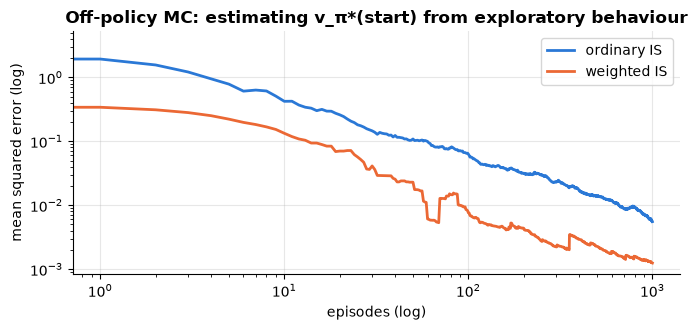

In [10]:
def off_policy_is_estimates(env, target_actions, n_episodes, seed, p_target=0.7):
    """Estimate v_pi(start) from behaviour-policy episodes with ordinary and weighted importance sampling.
    Behaviour b: take the target action with probability p_target, each other action with (1 - p_target) / 3."""
    rng = np.random.default_rng(seed); env.reset(seed=seed)
    num, den, ordinary, weighted = 0.0, 0.0, [], []
    for ep in range(n_episodes):
        s, _ = env.reset(); G, rho, done = 0.0, 1.0, False
        while not done:
            if rng.random() < p_target:                               # behaviour policy b
                a = int(target_actions[s])
            else:
                a = int((target_actions[s] + rng.integers(1, 4)) % 4)  # one of the three other actions
            b_prob = p_target if a == target_actions[s] else (1 - p_target) / 3
            rho *= (1.0 if a == target_actions[s] else 0.0) / b_prob  # pi(a|s) / b(a|s)
            if rho == 0.0:
                break            # the episode left pi*: its weight is 0 whatever happens next, so stop simulating
            s, r, terminated, truncated, _ = env.step(a)
            G += r; done = terminated or truncated
        num += rho * G; den += rho
        ordinary.append(num / (ep + 1))
        weighted.append(num / den if den > 0 else 0.0)
    return np.array(ordinary), np.array(weighted)

runs = [off_policy_is_estimates(env, policy_star, 1000, seed) for seed in range(100)]
ordinary = np.array([r[0] for r in runs]); weighted = np.array([r[1] for r in runs])
truth = V_true_star[env.start]
mse = lambda est: ((est - truth) ** 2).mean(axis=0)
print(f"After 1000 episodes (100 runs): ordinary IS mean {ordinary[:, -1].mean():.3f} ± {ordinary[:, -1].std():.3f} | "
      f"weighted IS mean {weighted[:, -1].mean():.3f} ± {weighted[:, -1].std():.3f} | truth {truth:.3f}")
plt.figure(figsize=(7, 3.4))
plt.plot(mse(ordinary), label="ordinary IS"); plt.plot(mse(weighted), label="weighted IS")
plt.yscale("log"); plt.xscale("log"); plt.xlabel("episodes (log)"); plt.ylabel("mean squared error (log)")
plt.title("Off-policy MC: estimating v_π*(start) from exploratory behaviour"); plt.legend(); plt.tight_layout(); plt.show()

**What just happened?** Both estimators learn about π* while the agent behaves exploratorily. Ordinary IS is unbiased, but an episode that happens to follow π* for $T$ steps gets the large weight $(1/0.7)^T$, and one that follows it for one step fewer gets 0, so the estimate jumps around (look at its spread across runs). Weighted IS normalises by the sum of the weights, so its estimate is always an average of real returns. Its spread across runs is about half that of ordinary IS, and its mean squared error is several times smaller for the same data. This mirrors Sutton & Barto's Figure 5.3 on a different MDP. (If the behaviour policy were uniform random, an episode would match π* for all ~6+ steps with probability below $4^{-6}$, and almost no episode would count at all.)

> ⚠️ **Common mistake:** using importance sampling when the behaviour policy gives probability 0 to an action that π can take. The ratio is then undefined: the behaviour policy must **cover** the target policy ($\pi(a\mid s) > 0 \Rightarrow b(a\mid s) > 0$).

**Complexity.** MC costs $O(T)$ per episode of length $T$ (plus $O(T)$ memory for the trajectory). Its estimates have no bootstrapping bias but high variance.

## 4. Temporal-difference learning (learn from every step)

> 💬 **In plain English:** instead of waiting for the end of the game, update your guess after every move using your guess for the next square, like updating your arrival-time estimate at every traffic light instead of only once you get home.

**TD(0) prediction:**
$$V(S_t) \leftarrow V(S_t) + \alpha\,\big[\underbrace{R_{t+1} + \gamma V(S_{t+1})}_{\text{TD target}} - V(S_t)\big].$$

The bracket is the **TD error** $\delta_t$. Using the estimate $V(S_{t+1})$ inside the target is called **bootstrapping**. It introduces bias but reduces variance compared with MC.

### 4.1 TD(0) vs MC on the random walk (Sutton & Barto, Example 6.2)
Five states A–E in a row, start in C, step left or right with probability ½. Exiting on the right gives +1, on the left 0. With γ = 1 the true values are $1/6, 2/6, \dots, 5/6$.

```
 [0] ← A  B  C  D  E → [+1]
            ↑ start
```

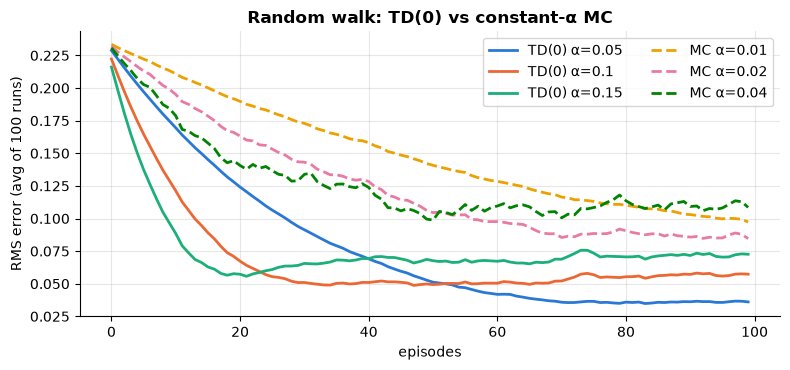

TD(0) estimates after 1000 episodes (α=0.02): [0.122 0.272 0.47  0.627 0.843] | true: [0.167 0.333 0.5   0.667 0.833]


In [11]:
class RandomWalk:
    """States 1..n are non-terminal; 0 and n+1 are terminal. Reward +1 only when exiting on the right
    (or -1 on the left if left_reward=-1, used in section 5)."""
    def __init__(self, n=5, left_reward=0.0):
        self.n, self.left_reward = n, left_reward
        self.rng = np.random.default_rng(0)
    def reset(self, seed=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed)
        self.s = (self.n + 1) // 2
        return self.s, {}
    def step(self, a=None):                           # the "policy" is fixed: a coin flip
        self.s += 1 if self.rng.random() < 0.5 else -1
        if self.s == self.n + 1:
            return self.s, 1.0, True, False, {}
        if self.s == 0:
            return self.s, self.left_reward, True, False, {}
        return self.s, 0.0, False, False, {}

def walk_episode(walk, seed=None):
    s, _ = walk.reset(seed=seed); traj, done = [], False
    while not done:
        s2, r, done, _, _ = walk.step()
        traj.append((s, r, s2, done)); s = s2
    return traj

def walk_runs(n_runs, n_episodes, n=5, left_reward=0.0):
    """Pre-generate the episodes of every run once. Every algorithm and step size then sees the SAME random walks
    ("common random numbers"), which makes the comparison fairer and the sweeps faster."""
    runs = []
    for seed in range(n_runs):
        walk = RandomWalk(n, left_reward); walk.reset(seed=seed)
        runs.append([walk_episode(walk) for _ in range(n_episodes)])
    return runs

def td0_walk(episodes, alpha, n=5):
    V = np.full(n + 2, 0.5); V[0] = V[-1] = 0.0
    errs = []
    for episode in episodes:
        for s, r, s2, done in episode:
            V[s] += alpha * (r + (0.0 if done else V[s2]) - V[s])       # TD(0) update after EVERY step
        errs.append(np.sqrt(np.mean((V[1:-1] - TRUE_WALK) ** 2)))
    return V, errs

def mc_walk(episodes, alpha, n=5):
    V = np.full(n + 2, 0.5); V[0] = V[-1] = 0.0
    errs = []
    for traj in episodes:
        G = traj[-1][1]                                                  # gamma = 1, only the final reward is non-zero
        for s, r, s2, done in traj:
            V[s] += alpha * (G - V[s])                                   # constant-alpha MC, after the episode
        errs.append(np.sqrt(np.mean((V[1:-1] - TRUE_WALK) ** 2)))
    return V, errs

TRUE_WALK = np.arange(1, 6) / 6
WALK5 = walk_runs(100, 100)                       # 100 runs x 100 episodes, reused by every curve
fig, ax = plt.subplots(figsize=(8, 3.8))
for alpha, style in [(0.05, "-"), (0.1, "-"), (0.15, "-")]:
    ax.plot(np.mean([td0_walk(eps, alpha)[1] for eps in WALK5], axis=0), style, label=f"TD(0) α={alpha}")
for alpha in [0.01, 0.02, 0.04]:
    ax.plot(np.mean([mc_walk(eps, alpha)[1] for eps in WALK5], axis=0), "--", label=f"MC α={alpha}")
ax.set_xlabel("episodes"); ax.set_ylabel("RMS error (avg of 100 runs)"); ax.set_title("Random walk: TD(0) vs constant-α MC")
ax.legend(ncol=2); plt.tight_layout(); plt.show()
V_td, _ = td0_walk(walk_runs(1, 1000)[0], 0.02)
print("TD(0) estimates after 1000 episodes (α=0.02):", V_td[1:-1].round(3), "| true:", TRUE_WALK.round(3))

**What just happened?** TD(0) (solid lines) reaches a lower error faster than MC (dashed) on this task, which is Sutton & Barto's Figure 6.2. TD makes use of the Markov structure: once it knows D is good, it can update C immediately from the step C→D, without waiting for the episode to finish. With a constant α neither method converges exactly; the error plateaus at a level set by α (smaller α = lower plateau but slower start).

### 4.2 Control: SARSA, Expected SARSA and Q-learning
Replace $V$ by $Q(s, a)$ and pick actions ε-greedily:

| Algorithm | TD target | On/off-policy |
|---|---|---|
| **SARSA** | $R + \gamma Q(S', A')$ with $A'$ the action actually taken next | on-policy (learns the value of the ε-greedy policy it follows) |
| **Expected SARSA** | $R + \gamma \sum_{a'} \pi(a'\mid S')\,Q(S', a')$ | either; lower variance than SARSA |
| **Q-learning** | $R + \gamma \max_{a'} Q(S', a')$ | off-policy (learns $q_*$ whatever it does) |

**CliffWalking** (Sutton & Barto Example 6.6) is a 4×12 grid. The start is bottom-left, the goal bottom-right, and the bottom row in between is a cliff. Every step costs −1; stepping into the cliff costs −100 and sends the agent back to the start. We use Gymnasium's built-in `CliffWalking-v1`.

In [12]:
cliff = gym.make("CliffWalking-v1", disable_env_checker=True)
print("CliffWalking:", cliff.observation_space, cliff.action_space, "| actions: 0=up 1=right 2=down 3=left")

def td_control(env, method, n_episodes=500, alpha=0.5, gamma=1.0, eps=0.1, seed=0, max_steps=1000):
    """Tabular SARSA / Expected SARSA / Q-learning with an epsilon-greedy behaviour policy."""
    rng = np.random.default_rng(seed)
    nS, nA = env.observation_space.n, env.action_space.n
    Q = np.zeros((nS, nA)); ep_returns = []
    for ep in range(n_episodes):
        s, _ = env.reset(seed=seed if ep == 0 else None)
        a = epsilon_greedy(Q[s], eps, rng)
        G = 0.0
        for t in range(max_steps):
            s2, r, terminated, truncated, _ = env.step(a)
            G += r
            a2 = epsilon_greedy(Q[s2], eps, rng)
            if terminated:
                target = r
            elif method == "sarsa":
                target = r + gamma * Q[s2, a2]
            elif method == "expected_sarsa":
                probs = np.full(nA, eps / nA)
                probs[np.flatnonzero(Q[s2] == Q[s2].max())] += (1 - eps) / np.sum(Q[s2] == Q[s2].max())
                target = r + gamma * probs @ Q[s2]
            elif method == "q_learning":
                target = r + gamma * Q[s2].max()
            Q[s, a] += alpha * (target - Q[s, a])
            s, a = s2, a2
            if terminated or truncated:
                break
        ep_returns.append(G)
    return Q, np.array(ep_returns)

t0 = time.time()
cliff_results = {m: [td_control(cliff, m, seed=sd) for sd in range(4)] for m in ["sarsa", "expected_sarsa", "q_learning"]}
print(f"Trained 3 algorithms x 4 seeds x 500 episodes in {time.time() - t0:.1f} s")

CliffWalking: Discrete(48) Discrete(4) | actions: 0=up 1=right 2=down 3=left


Trained 3 algorithms x 4 seeds x 500 episodes in 7.1 s


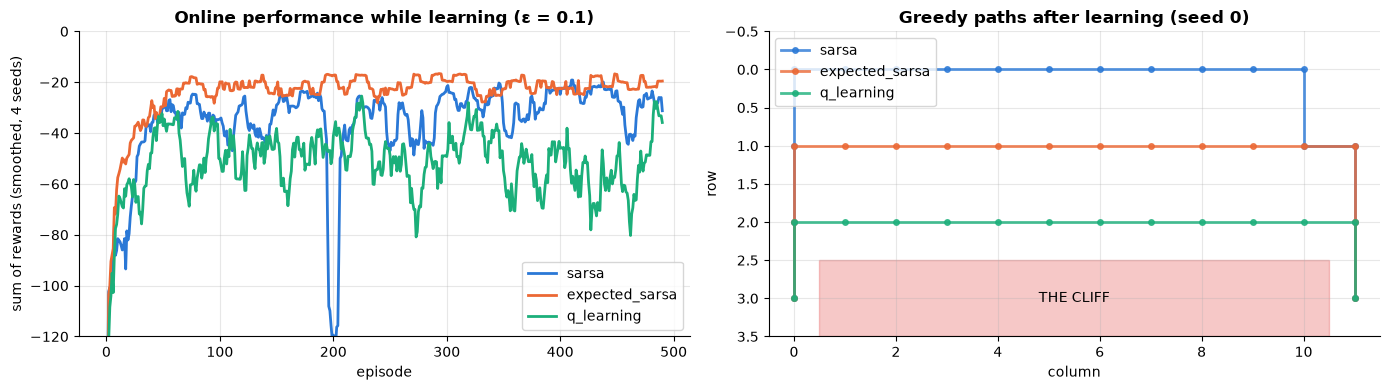

        method  mean online return (last 100 ep)  greedy path length  greedy return rows used by greedy path
         sarsa                             -26.9                  17            -17             [0, 1, 2, 3]
expected_sarsa                             -21.0                  15            -15                [1, 2, 3]
    q_learning                             -53.8                  13            -13                   [2, 3]


In [13]:
def smooth(x, k=10):
    return np.convolve(x, np.ones(k) / k, mode="valid")

def greedy_path(Q, start=36, goal=47, max_len=100):
    """Follow the greedy policy in the deterministic CliffWalking dynamics, using the env's model P."""
    P, s, path = cliff.unwrapped.P, start, [start]
    for _ in range(max_len):
        s = int(P[s][int(np.argmax(Q[s]))][0][1])
        path.append(s)
        if s == goal:
            break
    return path

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
summary = []
for m, runs_m in cliff_results.items():
    curves = np.array([smooth(r) for _, r in runs_m])
    axes[0].plot(curves.mean(0), label=m)
    path = greedy_path(runs_m[0][0])
    rows_used = sorted({p // 12 for p in path})
    summary.append({"method": m, "mean online return (last 100 ep)": np.mean([r[-100:].mean() for _, r in runs_m]),
                    "greedy path length": len(path) - 1, "greedy return": -(len(path) - 1), "rows used by greedy path": rows_used})
    xy = np.array([(p % 12, p // 12) for p in path])
    axes[1].plot(xy[:, 0], xy[:, 1], marker="o", ms=4, label=m, alpha=0.8)
axes[0].set_ylim(-120, 0); axes[0].set_xlabel("episode"); axes[0].set_ylabel("sum of rewards (smoothed, 4 seeds)")
axes[0].set_title("Online performance while learning (ε = 0.1)"); axes[0].legend()
axes[1].add_patch(plt.Rectangle((0.5, 2.5), 10, 1, color="#e34948", alpha=0.3)); axes[1].text(5.5, 3, "THE CLIFF", ha="center", va="center")
axes[1].set_xlim(-0.5, 11.5); axes[1].set_ylim(3.5, -0.5); axes[1].set_xlabel("column"); axes[1].set_ylabel("row")
axes[1].set_title("Greedy paths after learning (seed 0)"); axes[1].legend(loc="upper left")
plt.tight_layout(); plt.show()
cliff_table = pd.DataFrame(summary); print(cliff_table.round(1).to_string(index=False))

**What just happened?** This is the most famous picture in tabular RL (Sutton & Barto, Fig. 6.4):
- **Q-learning** learns the **optimal** path right along the cliff edge (13 steps, return −13), because its target uses $\max$, as if it will act greedily in future. But it *behaves* ε-greedily while learning, so it sometimes slips off the cliff, and its **online** return is worse.
- **SARSA** learns the value of the policy it actually follows, including its own random 10% moves, so it prefers a **safer path** further from the edge. Its greedy path is longer, but it falls less while learning, so its online return is higher.
- **Expected SARSA** averages over the next action instead of sampling it. It behaves like SARSA (safe) with less variance, so it can use a large α = 0.5 safely and often has the best online return.

Check the table: the online-return column and the "rows used" column show this trade-off in numbers. (Rows are numbered 0 at the top to 3 at the cliff row; the start and goal are in row 3.)

> 🎓 **Exam / interview tip:** "Why does SARSA take the safe path?" Because it is **on-policy**: it evaluates the ε-greedy policy, and next to the cliff ε-greedy sometimes steps off. If ε decays to 0, SARSA also converges to the optimal (edge) path.

**Complexity.** Each TD update is $O(1)$ (or $O(|\mathcal A|)$ for the max or expectation) and needs $O(|\mathcal S||\mathcal A|)$ memory for the table.

## 5. n-step TD and TD(λ)

> 💬 **In plain English:** look a few steps ahead (not one, not all) before trusting your own guess; this is usually the fastest way to learn.

The **n-step return** uses $n$ real rewards and then bootstraps:
$$G_{t:t+n} = R_{t+1} + \gamma R_{t+2} + \dots + \gamma^{n-1} R_{t+n} + \gamma^n V(S_{t+n}).$$
$n = 1$ is TD(0); $n = \infty$ is Monte Carlo.

**TD(λ)** averages *all* n-step returns with weights $(1-\lambda)\lambda^{n-1}$ (the **λ-return**). The **backward view** implements this online with an **eligibility trace** $e(s)$, a short-term memory of which states were visited recently:
$$e(s) \leftarrow \gamma\lambda\,e(s) + \mathbb 1[s = S_t], \qquad V(s) \leftarrow V(s) + \alpha\,\delta_t\,e(s)\ \ \forall s.$$

We use the **19-state random walk** with reward −1 on the left exit and +1 on the right (true values are $-0.9, -0.8, \dots, 0.9$), and measure the average RMS error over the first 10 episodes, as in Sutton & Barto, Figures 7.2 and 12.3.

Sweeps done in 9.8 s


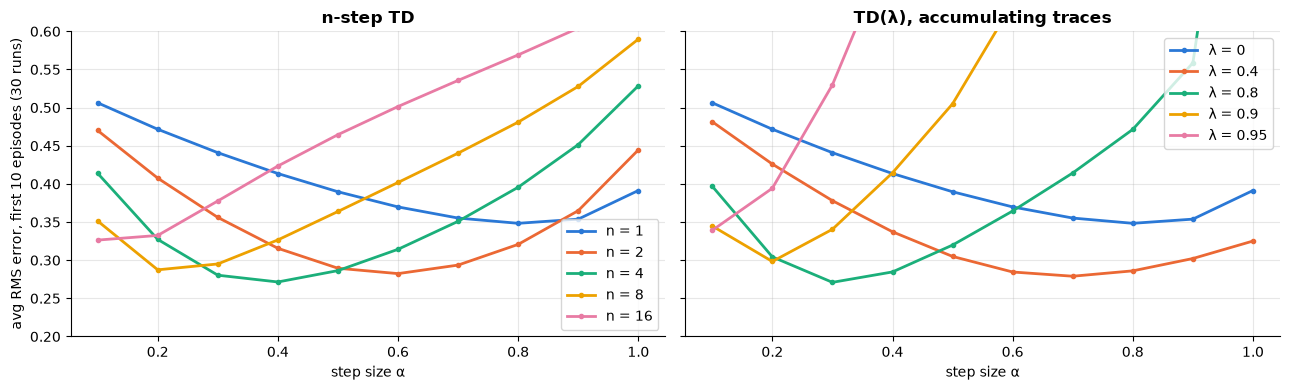

        best α  lowest error
n=1        0.8         0.348
n=2        0.6         0.282
n=4        0.4         0.271
n=8        0.2         0.287
n=16       0.1         0.326
λ=0        0.8         0.348
λ=0.4      0.7         0.279
λ=0.8      0.3         0.271
λ=0.9      0.2         0.298
λ=0.95     0.1         0.339


In [14]:
N_WALK = 19
TRUE_19 = np.arange(-(N_WALK - 1), N_WALK, 2) / (N_WALK + 1)     # -0.9 ... 0.9

def n_step_td(n, alpha, episodes, gamma=1.0):
    V = np.zeros(N_WALK + 2)
    errs = []
    for traj in episodes:                                  # each traj is a list of (s, r, s2, done)
        states = [traj[0][0]] + [x[2] for x in traj]       # S_0 ... S_T
        rewards = [x[1] for x in traj]                     # R_1 ... R_T
        T = len(rewards)
        for tau in range(T):                               # update the state visited at time tau
            end = min(tau + n, T)
            G = sum(gamma ** (k - tau) * rewards[k] for k in range(tau, end))
            if end < T:
                G += gamma ** n * V[states[end]]           # bootstrap if the episode has not ended yet
            V[states[tau]] += alpha * (G - V[states[tau]])
        errs.append(np.sqrt(np.mean((V[1:-1] - TRUE_19) ** 2)))
    return np.mean(errs)

def td_lambda(lam, alpha, episodes, gamma=1.0):
    V = np.zeros(N_WALK + 2)
    errs = []
    for episode in episodes:
        e = np.zeros_like(V)                               # eligibility traces reset each episode
        for s, r, s2, done in episode:
            delta = r + (0.0 if done else gamma * V[s2]) - V[s]
            e *= gamma * lam; e[s] += 1.0                  # accumulating trace
            V += alpha * delta * e                         # every recently visited state shares the credit
        errs.append(np.sqrt(np.mean((V[1:-1] - TRUE_19) ** 2)))
    return np.mean(errs)

# Note: this n-step implementation updates after the episode using the V values at update time,
# an offline variant that is easy to read; the online algorithm of Sutton & Barto (Section 7.1) gives very similar curves.
alphas = np.linspace(0.0, 1.0, 11)[1:]
t0 = time.time()
WALK19 = walk_runs(30, 10, n=N_WALK, left_reward=-1.0)          # 30 runs x 10 episodes, shared by all settings
nstep_curves = {n: [np.mean([n_step_td(n, a, eps) for eps in WALK19]) for a in alphas] for n in [1, 2, 4, 8, 16]}
lambda_curves = {lam: [np.mean([td_lambda(lam, a, eps) for eps in WALK19]) for a in alphas] for lam in [0, 0.4, 0.8, 0.9, 0.95]}
print(f"Sweeps done in {time.time() - t0:.1f} s")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for n, c in nstep_curves.items():
    axes[0].plot(alphas, c, marker="o", ms=3, label=f"n = {n}")
for lam, c in lambda_curves.items():
    axes[1].plot(alphas, c, marker="o", ms=3, label=f"λ = {lam}")
for ax, t in zip(axes, ["n-step TD", "TD(λ), accumulating traces"]):
    ax.set_xlabel("step size α"); ax.set_title(t); ax.legend(); ax.set_ylim(0.2, 0.6)
axes[0].set_ylabel("avg RMS error, first 10 episodes (30 runs)")
plt.tight_layout(); plt.show()
best = {f"n={n}": (alphas[int(np.argmin(c))], min(c)) for n, c in nstep_curves.items()}
best.update({f"λ={l}": (alphas[int(np.argmin(c))], min(c)) for l, c in lambda_curves.items()})
print(pd.DataFrame(best, index=["best α", "lowest error"]).T.round(3).to_string())

**What just happened?** Intermediate settings win. In the n-step plot, $n = 1$ (pure TD) learns slowly because credit moves back one state per episode. Very large $n$ behaves like Monte Carlo and is noisy, so it needs a tiny α. The best $n$ is in the middle (around 4 here). TD(λ) shows the same U-shapes: λ between about 0.4 and 0.8 gives the lowest error, and large λ with large α blows up (the curves leave the top of the plot). In practice this is why PPO uses **GAE(λ)** with λ ≈ 0.95 (see the next notebook).

> ⚠️ **Common mistake:** forgetting to reset eligibility traces at the start of each episode, or using a large α with λ close to 1. Accumulating traces then add many updates to the same state and the values diverge.

## 6. Exploration strategies and honest learning curves

> 💬 **In plain English:** to find the treasure you must sometimes try paths that do not look best yet; different ways of being curious work very differently.

Our test is a **sparse-reward maze**: 0 reward everywhere except +1 at the goal, γ = 0.95, at most 200 steps per episode. Until the agent finds the goal once, every action looks equally good. We compare four Q-learning variants:

| Strategy | Rule |
|---|---|
| constant ε | ε-greedy with ε = 0.1 |
| ε-decay | ε falls linearly from 1.0 to 0.05 over the first 60 episodes |
| optimistic initialisation | start with $Q = 1$ (more than any real value) and act **greedily**; disappointment drives exploration |
| UCB-style bonus | act greedily on $Q(s,a) + c\sqrt{\ln N(s) / N(s,a)}$ (count-based bonus, as in UCB1 from [bandits](07_multi_armed_bandits.ipynb)) |

RL results vary a lot between random seeds, so we run **10 seeds** per strategy and draw the mean with a **95% confidence band** (mean ± 1.96 × standard error).

4 strategies x 10 seeds in 9.6 s. Shortest possible path: 19 steps


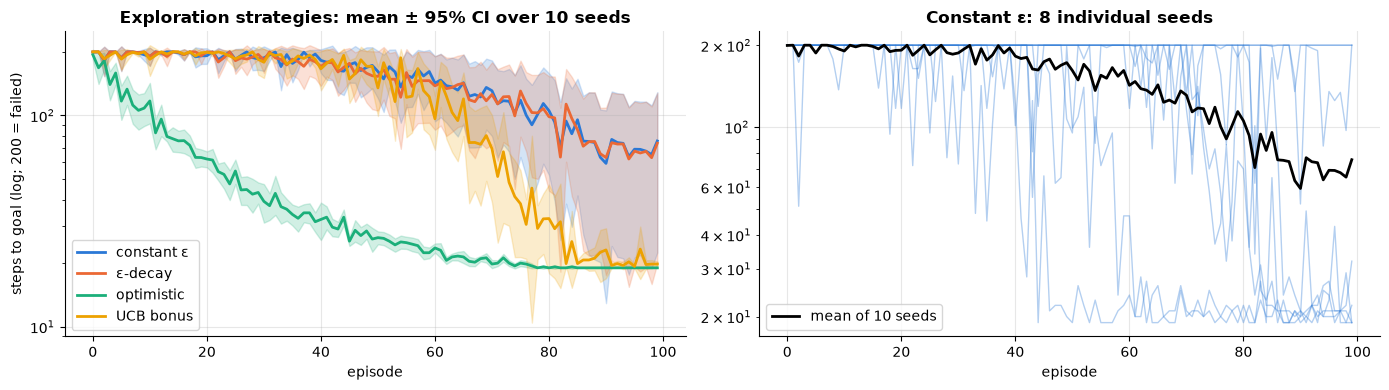

            total steps (all episodes)  failed episodes (hit 200)  mean steps, last 20 ep
constant ε                     14986.5                       63.3                    76.2
ε-decay                        14781.7                       62.8                    76.4
optimistic                      4419.5                        2.1                    19.0
UCB bonus                      12753.3                       47.0                    22.4


In [15]:
MAZE = ["S....#....",
        ".###.#.##.",
        ".#...#..#.",
        ".#.###.##.",
        ".#........",
        ".####.###.",
        "......#..G"]
maze = GridWorld(MAZE, slip=0.0, step_reward=0.0, goal_reward=1.0, max_steps=200)

def q_learning_explore(env, strategy, n_episodes=100, alpha=0.5, gamma=0.95, seed=0, c=0.5):
    rng = np.random.default_rng(seed)
    Q = np.ones((env.n_states, 4)) if strategy == "optimistic" else np.zeros((env.n_states, 4))
    N = np.zeros((env.n_states, 4)); steps = []
    for ep in range(n_episodes):
        s, _ = env.reset(seed=seed if ep == 0 else None); done = False
        eps = {"constant ε": 0.1, "ε-decay": max(0.05, 1.0 - ep / 60), "optimistic": 0.0, "UCB bonus": 0.0}[strategy]
        while not done:
            if strategy == "UCB bonus":
                bonus = c * np.sqrt(np.log(N[s].sum() + 1) / (N[s] + 1e-9))
                scores = Q[s] + np.where(N[s] == 0, 1e9, bonus)       # untried actions first
                best = np.flatnonzero(scores == scores.max()); a = int(best[rng.integers(len(best))])
            else:
                a = epsilon_greedy(Q[s], eps, rng)
            s2, r, terminated, truncated, _ = env.step(a)
            N[s, a] += 1
            Q[s, a] += alpha * (r + (0.0 if terminated else gamma * Q[s2].max()) - Q[s, a])
            s, done = s2, terminated or truncated
        steps.append(env.t)
    return np.array(steps)

STRATEGIES = ["constant ε", "ε-decay", "optimistic", "UCB bonus"]
t0 = time.time()
explore = {st: np.array([q_learning_explore(maze, st, seed=sd) for sd in range(10)]) for st in STRATEGIES}
print(f"4 strategies x 10 seeds in {time.time() - t0:.1f} s. Shortest possible path: ", end="")
V_maze, pol_maze, _ = value_iteration(maze, gamma=0.95)
print(len(rollout(maze, lambda s: int(pol_maze[s]))[0]), "steps")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for i, st in enumerate(STRATEGIES):
    m = explore[st].mean(0); se = explore[st].std(0, ddof=1) / np.sqrt(len(explore[st]))
    axes[0].plot(m, label=st, color=PALETTE[i]); axes[0].fill_between(range(len(m)), m - 1.96 * se, m + 1.96 * se, alpha=0.2, color=PALETTE[i])
for curve in explore["constant ε"][:8]:
    axes[1].plot(curve, color=PALETTE[0], alpha=0.35, lw=1)
axes[1].plot(explore["constant ε"].mean(0), color="black", label="mean of 10 seeds")
axes[0].set_yscale("log"); axes[0].set_xlabel("episode"); axes[0].set_ylabel("steps to goal (log; 200 = failed)")
axes[0].set_title("Exploration strategies: mean ± 95% CI over 10 seeds"); axes[0].legend()
axes[1].set_yscale("log"); axes[1].set_xlabel("episode"); axes[1].set_title("Constant ε: 8 individual seeds"); axes[1].legend()
plt.tight_layout(); plt.show()
explore_table = pd.DataFrame({st: {"total steps (all episodes)": explore[st].sum(1).mean(),
                                   "failed episodes (hit 200)": (explore[st] >= 200).sum(1).mean(),
                                   "mean steps, last 20 ep": explore[st][:, -20:].mean()} for st in STRATEGIES}).T
print(explore_table.round(1).to_string())

**What just happened?** Read the plot and the table together:
- **Constant ε** and **ε-decay** fail most episodes (they hit the 200-step limit in about 60 of 100 episodes). On an all-zero table, ε-greedy with random tie-breaking is a **random walk**, and a random walk rarely crosses this maze in 200 steps. Nothing is learned until the goal has been reached once. ε-decay starting at ε = 1 is literally random at first, so it is no better here.
- The **UCB bonus** prefers untried actions *in the current cell*, which helps a little, and once the goal is known it settles near the shortest path. But the bonus is only used to choose, never propagated: the agent knows which action *here* is untried, not which *distant region* is unexplored.
- **Optimistic initialisation** wins by far: every untried state–action looks worth 1, and that optimism **propagates** through the $\max$ in the Q-learning target, so the agent is pulled towards unexplored regions anywhere in the maze ("deep exploration"). It almost never fails and ends on the shortest path (19 steps), with no ε to tune.
- The right panel shows why seeds matter: individual runs differ wildly, and a single-seed comparison could rank the strategies in almost any order.

> 🎓 **Exam / interview tip:** "Optimism in the face of uncertainty" is the principle behind UCB, optimistic initialisation and many exploration bonuses (e.g. count-based and curiosity bonuses in deep RL). Note that optimistic initial values only drive exploration at the start, so they do not help in non-stationary problems.

## 7. Dyna-Q: learning a model and planning with it

> 💬 **In plain English:** remember what happened and replay it in your head to learn much faster from the same real experience, like a chess player who replays a game afterwards.

**Dyna-Q** (Sutton 1990) mixes three processes:
1. **Direct RL:** a normal Q-learning update from each real step.
2. **Model learning:** store `model[(s, a)] = (r, s')` (deterministic world).
3. **Planning:** $n$ times per real step, pick a previously seen $(s, a)$ at random, ask the model for $(r, s')$, and do a Q-learning update on that *simulated* experience.

We use the **Dyna maze** of Sutton & Barto (Example 8.1): a 6×9 grid with walls, reward +1 at the goal, γ = 0.95, α = 0.1, ε = 0.1.

Dyna-Q runs finished in 4.2 s


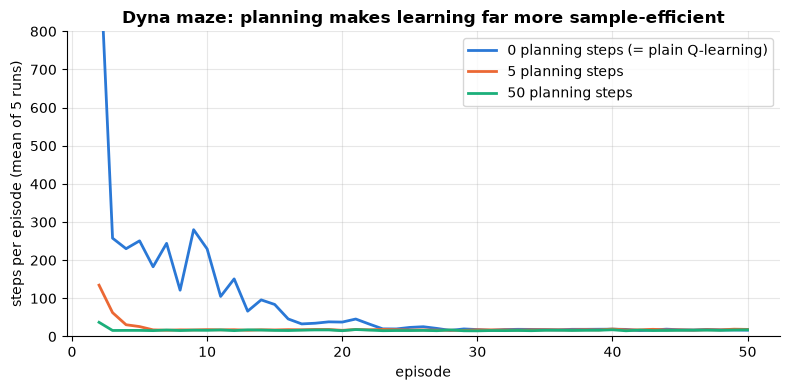

      episode 1  episode 2  episode 5  real steps, episodes 2-50
n=0       693.0     1049.0      251.0                     4138.0
n=5       345.0      135.0       26.0                     1042.0
n=50     1083.0       37.0       16.0                      814.0


In [16]:
DYNA_MAZE = [".......#G",
             "..#....#.",
             "S.#....#.",
             "..#......",
             ".....#...",
             "........."]
dmaze = GridWorld(DYNA_MAZE, slip=0.0, step_reward=0.0, goal_reward=1.0, max_steps=3000)

def dyna_q(env, n_planning, n_episodes=50, alpha=0.1, gamma=0.95, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, 4)); model = {}; steps = []
    for ep in range(n_episodes):
        s, _ = env.reset(seed=seed if ep == 0 else None); done = False
        while not done:
            a = epsilon_greedy(Q[s], eps, rng)
            s2, r, terminated, truncated, _ = env.step(a)
            Q[s, a] += alpha * (r + (0.0 if terminated else gamma * Q[s2].max()) - Q[s, a])   # (1) direct RL
            model[(s, a)] = (r, s2, terminated)                                               # (2) model learning
            keys = list(model)
            for _ in range(n_planning):                                                       # (3) planning
                ps, pa = keys[rng.integers(len(keys))]
                pr, ps2, pdone = model[(ps, pa)]
                Q[ps, pa] += alpha * (pr + (0.0 if pdone else gamma * Q[ps2].max()) - Q[ps, pa])
            s, done = s2, terminated or truncated
        steps.append(env.t)
    return np.array(steps)

t0 = time.time()
dyna = {n: np.array([dyna_q(dmaze, n, seed=sd) for sd in range(5)]) for n in [0, 5, 50]}
print(f"Dyna-Q runs finished in {time.time() - t0:.1f} s")
plt.figure(figsize=(8, 4))
for n, arr in dyna.items():
    plt.plot(range(2, 51), arr.mean(0)[1:], label=f"{n} planning steps" + (" (= plain Q-learning)" if n == 0 else ""))
plt.xlabel("episode"); plt.ylabel("steps per episode (mean of 5 runs)"); plt.ylim(0, 800)
plt.title("Dyna maze: planning makes learning far more sample-efficient"); plt.legend(); plt.tight_layout(); plt.show()
dyna_table = pd.DataFrame({f"n={n}": {"episode 1": arr[:, 0].mean(), "episode 2": arr[:, 1].mean(), "episode 5": arr[:, 4].mean(),
                                      "real steps, episodes 2-50": arr[:, 1:].sum(1).mean()} for n, arr in dyna.items()}).T
print(dyna_table.round(0).to_string())

**What just happened?** The first episode is a blind random search for everybody (hundreds to over a thousand steps, depending on luck), because all rewards are 0 until the goal is found once, so planning has nothing to propagate. After that, plain Q-learning ($n = 0$) moves the goal's value back by only one state per episode, so it needs dozens of episodes. With $n = 50$ planning steps, the stored experience is replayed so many times that the whole path is learned almost **within the second episode**. Compare the "real steps, episodes 2–50" column (episode 1 is excluded because it is pure luck): the planners need far fewer interactions with the world. This is Sutton & Barto's Figure 8.2. The price is compute: each real step costs $n + 1$ updates.

> 🎓 **Exam / interview tip:** sample efficiency vs compute is the core trade-off of model-based RL. If real experience is expensive (robots, patients, money) and compute is cheap, plan with a model. A wrong model can mislead the planner, though; Sutton & Barto's Dyna-Q+ adds an exploration bonus for state–actions not tried for a long time to handle changing worlds.

## 8. Reward shaping: a pitfall and the safe fix

> 💬 **In plain English:** giving extra points for 'progress' can backfire, because the agent farms the points instead of finishing; there is a safe way to do it.

**Reward shaping** adds an extra term $F$ to the reward to speed up learning. Designers often reward "progress", but a careless bonus can create a **positive reward cycle** that is worth more than finishing the task. This is a classic case of **reward hacking** (OpenAI's 2016 *CoastRunners* boat circled forever collecting points instead of finishing the race).

**Potential-based shaping** (Ng, Harada & Russell, 1999) uses
$$F(s, s') = \gamma\,\Phi(s') - \Phi(s)$$
for any function Φ of the state. Along any trajectory the bonuses **telescope**: $\sum_t \gamma^t F = \gamma^T\Phi(s_T) - \Phi(s_0)$. That depends only on the start and end states, so the optimal policy cannot change (taking $\Phi(\text{terminal}) = 0$). Any cycle of length $k$ earns a net shaping reward of $(\gamma^k - 1)\Phi(s)$, which is $\le 0$ when $\Phi \ge 0$, so a non-negative potential cannot be farmed in a loop.

A good potential is a rough guess of the state's value. Here we use $\Phi(s) = 10\,\gamma^{d(s)}$, where $d$ is the Manhattan distance to the goal: the goal reward discounted by the fewest steps that could possibly reach it (an optimistic heuristic, like A*'s), with $\Phi = 0$ at the terminal goal.

Our corridor: start on the left, goal (+10) on the right, γ = 0.99. A designer adds **+1 every time the agent enters the checkpoint `C`** "to encourage going right".

In [17]:
CORRIDOR = ["S...C.....G"]
base = GridWorld(CORRIDOR, slip=0.0, step_reward=0.0, goal_reward=10.0, max_steps=100)
GAMMA_SHAPE = 0.99
goal_col = CORRIDOR[0].index("G"); ckpt = base.index[(0, CORRIDOR[0].index("C"))]

def reshape(env, extra):
    """Return a copy of env whose rewards are r + extra(s, s2) (the extra term is added to every transition)."""
    new = GridWorld(env.layout, slip=env.slip, step_reward=env.step_reward, goal_reward=env.bonus["G"], max_steps=env.max_steps)
    new.P = {s: {a: [(p, s2, r + extra(s, s2), d) for p, s2, r, d in env.P[s][a]] for a in env.P[s]} for s in env.P}
    return new

naive = reshape(base, lambda s, s2: 1.0 if (s2 == ckpt and s != ckpt and s not in base.terminal) else 0.0)   # +1 for ENTERING C
def make_phi(env, goal_rc, value=10.0):
    """Phi(s) = value * gamma^(Manhattan distance to the goal); 0 at terminal states."""
    return lambda s: 0.0 if s in env.terminal else value * GAMMA_SHAPE ** (abs(goal_rc[0] - env.cells[s][0]) + abs(goal_rc[1] - env.cells[s][1]))
phi = make_phi(base, (0, goal_col))
potential = reshape(base, lambda s, s2: 0.0 if s in base.terminal else GAMMA_SHAPE * phi(s2) - phi(s))

rows = []
for name, e in [("original reward", base), ("naive +1 checkpoint bonus", naive), ("potential-based shaping", potential)]:
    V_e, pol_e, _ = value_iteration(e, gamma=GAMMA_SHAPE)
    traj, _ = rollout(e, lambda s: int(pol_e[s]))
    reached = e.cells[e.s][1] == goal_col
    true_return = sum(GAMMA_SHAPE ** t * (10.0 if (t == len(traj) - 1 and reached) else 0.0) for t in range(len(traj)))
    rows.append({"reward used for training": name, "greedy policy": "".join(ARROWS[int(pol_e[s])] for s in range(e.n_states - 1)),
                 "reaches goal?": reached, "steps": len(traj), "TRUE discounted return": round(true_return, 3)})
    if name == "original reward":
        pol_base = pol_e
    if name == "potential-based shaping":
        assert np.array_equal(pol_e[:-1], pol_base[:-1]), "potential-based shaping must not change the optimal policy"
shaping_table = pd.DataFrame(rows); print(shaping_table.to_string(index=False))
print("\nFrom C: farming the bonus forever is worth γ/(1-γ²) ≈", round(GAMMA_SHAPE / (1 - GAMMA_SHAPE ** 2), 1),
      " vs. walking 6 steps to the goal: 10·γ^5 ≈", round(10 * GAMMA_SHAPE ** 5, 2))

 reward used for training greedy policy  reaches goal?  steps  TRUE discounted return
          original reward    →→→→→→→→→→           True     10                   9.135
naive +1 checkpoint bonus    →→→→→←←←←←          False    100                   0.000
  potential-based shaping    →→→→→→→→→→           True     10                   9.135

From C: farming the bonus forever is worth γ/(1-γ²) ≈ 49.7  vs. walking 6 steps to the goal: 10·γ^5 ≈ 9.51


**What just happened?** With the naive bonus, the optimal policy is to **step back and forth across the checkpoint forever** (→ then ←), until the 100-step time limit. Each entry pays +1, and an endless stream of +1 every second step is worth $\gamma/(1-\gamma^2) \approx 50$ from the checkpoint, far more than the discounted +10 for finishing (about 9.5). The agent is doing exactly what the reward says, not what the designer meant, so its *true* return is 0. Potential-based shaping gives exactly the same policy as the original reward (we asserted it) while still giving a dense "you are getting closer" signal.

Does safe shaping actually speed up *learning*? It depends on Φ. Wiewiora (2003) proved that Q-learning with potential-based shaping behaves exactly like Q-learning **initialised with $Q_0(s,a) = \Phi(s)$**. So a potential that rates states too low acts like *pessimistic* initial values. A popular choice, $\Phi = -d(s)$ ("minus the distance"), is such a case: with γ < 1, staying put earns $(\gamma-1)\Phi(s) = (1-\gamma)\,d(s) > 0$, a small reward for bumping into walls. Let's compare three agents on a 16-cell corridor.

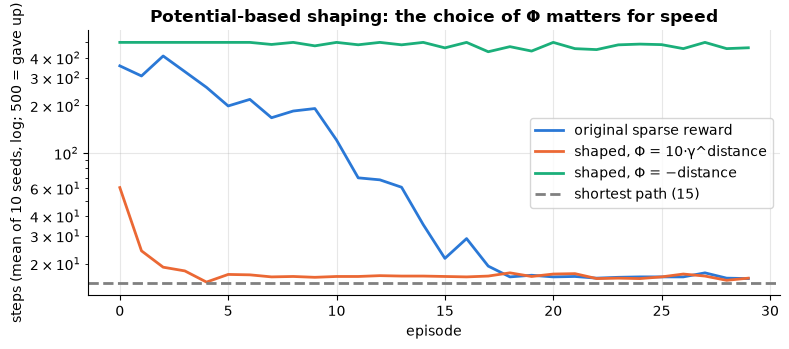

                           total steps, 30 episodes  episodes hitting the 500-step limit  mean steps, last 10 episodes
original sparse reward                       3240.2                                  2.2                          16.5
shaped, Φ = 10·γ^distance                     553.0                                  0.0                          16.5
shaped, Φ = −distance                       14470.8                                 27.9                         473.6


In [18]:
LONG = ["S" + "." * 14 + "G"]
long_base = GridWorld(LONG, slip=0.0, step_reward=0.0, goal_reward=10.0, max_steps=500)
goal_long = (0, len(LONG[0]) - 1)
phi_value = make_phi(long_base, goal_long)                                   # optimistic: 10 * gamma^distance
phi_minus = lambda s: 0.0 if s in long_base.terminal else -float(abs(goal_long[1] - long_base.cells[s][1]))   # minus the distance
shaped_env = {name: reshape(long_base, lambda s, s2, f=f: 0.0 if s in long_base.terminal else GAMMA_SHAPE * f(s2) - f(s))
              for name, f in [("Φ = 10·γ^distance", phi_value), ("Φ = −distance", phi_minus)]}

def q_learning_steps(env, n_episodes=30, alpha=0.5, eps=0.1, seed=0):
    rng = np.random.default_rng(seed); Q = np.zeros((env.n_states, 4)); steps = []
    for ep in range(n_episodes):
        s, _ = env.reset(seed=seed if ep == 0 else None); done = False
        while not done:
            a = epsilon_greedy(Q[s], eps, rng)
            s2, r, term, trunc, _ = env.step(a)
            Q[s, a] += alpha * (r + (0.0 if term else GAMMA_SHAPE * Q[s2].max()) - Q[s, a])
            s, done = s2, term or trunc
        steps.append(env.t)
    return np.array(steps)

shaping_runs = {"original sparse reward": np.array([q_learning_steps(long_base, seed=sd) for sd in range(10)])}
for name, e in shaped_env.items():
    shaping_runs["shaped, " + name] = np.array([q_learning_steps(e, seed=sd) for sd in range(10)])
plt.figure(figsize=(8, 3.6))
for name, arr in shaping_runs.items():
    plt.plot(arr.mean(0), label=name)
plt.axhline(15, color="grey", ls="--", label="shortest path (15)")
plt.yscale("log"); plt.xlabel("episode"); plt.ylabel("steps (mean of 10 seeds, log; 500 = gave up)")
plt.title("Potential-based shaping: the choice of Φ matters for speed"); plt.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({name: {"total steps, 30 episodes": arr.sum(1).mean(), "episodes hitting the 500-step limit": (arr >= 500).sum(1).mean(),
                           "mean steps, last 10 episodes": arr[:, -10:].mean()} for name, arr in shaping_runs.items()}).T.round(1).to_string())

**What just happened?**
- **No shaping:** the first episode is a long random walk before the +10 is found, then the value creeps back along the corridor.
- **Φ = 10·γ^distance:** a step right earns exactly 0 shaping reward, while any other move earns a negative one. Untried actions (still at 0) therefore always look at least as good as known bad ones, and the agent walks almost straight to the goal from the first episode.
- **Φ = −distance:** bumping into the corridor walls pays a small positive shaping reward, so the greedy agent learns to bump in place. Within 30 episodes it is still stuck in most episodes (see the table), far worse than no shaping at all. The theorem guarantees that the *optimal* policy is unchanged, so with enough exploration it would get there, but nothing guarantees *fast* learning. Same "safe" shaping, very different speed.

> ⚠️ **Common mistake:** rewarding *being in* a good state (or entering it) rather than *improving* a potential. Any state-based bonus that can be collected repeatedly can be farmed. RLHF reward models have the same weakness: a policy optimised hard against a learned reward finds outputs the reward model over-scores (**reward hacking**). That is why RLHF and DPO keep a KL penalty to a reference model (see [`08_LLM/12_alignment_techniques`](../08_LLM/12_alignment_techniques.ipynb)).

## 9. Summary table

> 💬 **In plain English:** one table to compare every method in this notebook.

| Method | Needs model? | Bootstraps? | On/off-policy | Update when | Main strength | Main weakness |
|---|---|---|---|---|---|---|
| Policy evaluation / iteration | yes | yes | n/a | sweep over all states | exact, few iterations | needs $P$; $O(\lvert\mathcal S\rvert^2\lvert\mathcal A\rvert)$ per sweep |
| Value iteration | yes | yes | n/a | sweep | simple, provably converges | slow when γ → 1 |
| First-visit MC | no | no | on (or off with IS) | end of episode | unbiased, no Markov assumption needed | high variance, episodic only |
| MC + importance sampling | no | no | off | end of episode | learns from other policies' data | variance explodes with long episodes (weighted IS helps) |
| TD(0) / SARSA | no | yes | on | every step | low variance, online | biased by its own estimates |
| Expected SARSA | no | yes | on/off | every step | lower variance than SARSA | $O(\lvert\mathcal A\rvert)$ per update |
| Q-learning | no | yes | off | every step | learns $q_*$ while exploring | maximisation bias, risky online behaviour |
| n-step TD / TD(λ) | no | partly | on | every step (traces) | tunable bias–variance trade-off | extra hyperparameter (n or λ) |
| Dyna-Q | learns one | yes | off | every step + n planning | very sample-efficient | compute cost; wrong models mislead |

Convergence facts worth memorising: tabular Q-learning converges to $q_*$ with probability 1 if every $(s,a)$ is visited infinitely often and the step sizes satisfy $\sum\alpha_t = \infty,\ \sum\alpha_t^2 < \infty$ (Watkins & Dayan, 1992). SARSA converges to $q_*$ under the same conditions if the policy is also **GLIE** (greedy in the limit with infinite exploration), for example ε-greedy with $\varepsilon_t = 1/t$.

## 10. 🔗 How this connects to modern AI

> 💬 **In plain English:** the same ideas power deep RL, AlphaZero, recommender evaluation and the alignment of chatbots.

- **Deep RL is tabular RL with a neural network instead of a table.** DQN is Q-learning plus a replay buffer (the Dyna idea of reusing experience) and a target network; PPO uses TD(λ)-style **GAE** advantages. Next notebook: [`10_deep_rl_on_cpu`](10_deep_rl_on_cpu.ipynb).
- **Model-based planning** (Dyna) grew into **AlphaZero / MuZero** (learned models plus tree search) and **world models** (Dreamer), and it is how LLM agents "think before acting" ([`10_Agents/02_memory_and_planning`](../10_Agents/02_memory_and_planning.ipynb)).
- **Reward hacking** in section 8 is the same failure that RLHF must guard against. The KL-to-reference term in RLHF/DPO plays a similar protective role to potential-based shaping: it limits how far the policy can exploit the reward ([`08_LLM/12_alignment_techniques`](../08_LLM/12_alignment_techniques.ipynb), and the hands-on DPO in [`08_LLM/21_fine_tuning_hands_on_cpu`](../08_LLM/21_fine_tuning_hands_on_cpu.ipynb)).
- **Off-policy evaluation with importance sampling** is used to evaluate a new recommender or ad policy from logged data before deploying it ([`03_Machine_Learning/09_recommendation_systems`](../03_Machine_Learning/09_recommendation_systems/02_industry_product_recommender.ipynb)).
- **Exploration bonuses** (UCB) are the basis of the bandit algorithms in [`07_multi_armed_bandits`](07_multi_armed_bandits.ipynb) and of MCTS's UCT rule in AlphaGo.
- **Operations research:** the inventory problem in [`08_industry_inventory_control_with_rl`](08_industry_inventory_control_with_rl.ipynb) is an MDP that could be solved with the value iteration code above when the state space is small.

## 11. Recap

> 💬 **In plain English:** the key points, some practice, and where to read more.

- An **MDP** is (states, actions, $P$, $R$, γ); a Gymnasium-style environment exposes `reset` and `step` and, for toy problems, the model `P`.
- **DP** (policy evaluation, policy iteration, value iteration) computes exact values from the model; our values matched AIMA's textbook utilities and an exact linear solve.
- **Monte Carlo** averages complete returns: unbiased but noisy; **importance sampling** enables off-policy evaluation, and **weighted IS** has much lower variance.
- **TD** methods bootstrap from the next estimate and learn online. **Q-learning** learns the optimal (cliff-edge) path; **SARSA** learns the safer path of the policy it actually follows.
- **n-step TD and TD(λ)** interpolate between TD and MC; intermediate n or λ learns fastest.
- **Exploration** matters most with sparse rewards; optimism and count-based bonuses explore systematically. Always compare over many seeds with confidence bands.
- **Dyna-Q** reuses experience through a learned model and needs far fewer real steps.
- **Reward shaping** can create exploitable loops; **potential-based shaping** is provably safe.

## Practice problems

**1. (Conceptual, easy)** On CliffWalking, why does Q-learning learn the path along the cliff edge while SARSA learns a safer one? What happens if ε decays to 0?

<details><summary>Show solution</summary>

Q-learning's target uses $\max_{a'} Q(s', a')$, so it learns the value of the **greedy** policy, for which walking along the edge is optimal (13 steps). But it **behaves** ε-greedily, and on the edge a random "down" action means −100. SARSA's target uses the action actually taken next, so it learns the value of the ε-greedy policy *including* its random moves; for that policy, cells next to the cliff are dangerous and have low value, so it learns to keep a row or two away. If ε → 0 over time (GLIE), both converge to the edge path.

</details>

**2. (Calculation, easy)** Q(s,a) = 0.5, reward −1, γ = 0.9, α = 0.1, and in the next state $\max_{a'} Q(s',a') = 2.0$. Do one Q-learning update. Then do the SARSA update if the action actually taken next has Q(s′,a′) = 1.0.

<details><summary>Show solution</summary>

TD error δ = r + γ max Q(s′,·) − Q(s,a) = −1 + 0.9 × 2.0 − 0.5 = 0.3. New Q(s,a) = 0.5 + 0.1 × 0.3 = **0.53**.

For SARSA with Q(s′, a′) = 1.0 for the action actually taken: δ = −1 + 0.9 × 1.0 − 0.5 = −0.6, so Q(s,a) = 0.5 − 0.06 = **0.44**.

</details>

**3. (Calculation, medium)** A two-state chain under a fixed policy: from A you always get reward 1 and move to B; from B you get reward 0 and move to A or stay in B with probability ½ each. With γ = 0.9, solve the Bellman equations for $v(A)$ and $v(B)$ by hand, then check with NumPy.

<details><summary>Show solution</summary>

Write $v = r_\pi + \gamma P_\pi v$ with $\gamma = 0.9$:

$v_A = 1 + 0.9\,v_B$ and $v_B = 0 + 0.9\,(0.5 v_A + 0.5 v_B)$.

From the second: $v_B (1 - 0.45) = 0.45 v_A$, so $v_B = \frac{0.45}{0.55} v_A = \frac{9}{11} v_A$. Substituting: $v_A = 1 + 0.9 \cdot \frac{9}{11} v_A$, so $v_A (1 - \frac{81}{110}) = 1$, giving $v_A = \frac{110}{29} \approx 3.793$ and $v_B = \frac{90}{29} \approx 3.103$.

```python
import numpy as np
P = np.array([[0, 1], [0.5, 0.5]]); r = np.array([1.0, 0.0])
v = np.linalg.solve(np.eye(2) - 0.9 * P, r)
print(v)              # [3.7931 3.1034]
```

</details>

**4. (Proof, medium)** Show that potential-based shaping $F = \gamma\Phi(s') - \Phi(s)$ does not change the optimal policy in an episodic task with $\Phi(\text{terminal}) = 0$. Why does the naive checkpoint bonus fail this argument?

<details><summary>Show solution</summary>

For any trajectory $s_0, s_1, \dots, s_T$ the discounted sum of shaping terms is

$\sum_{t=0}^{T-1} \gamma^t \big(\gamma\Phi(s_{t+1}) - \Phi(s_t)\big) = \gamma^T \Phi(s_T) - \Phi(s_0)$

(every intermediate term appears once with + and once with −). With $\Phi(\text{terminal}) = 0$, the shaped return of every complete episode equals the original return minus the constant $\Phi(s_0)$. So $Q'(s,a) = Q(s,a) - \Phi(s)$ for every $s$: the ranking of actions in each state is unchanged, and so is the optimal policy. The naive checkpoint bonus is not of this form: a loop $C \to C^- \to C$ earns $+1$ each time, so it does not telescope.

</details>

**5. (Coding, medium)** Implement **Double Q-learning** (two tables, each updated with the other's evaluation of its own argmax) and run it on `cliff`. Does the greedy path still have 13 steps?

<details><summary>Show solution</summary>

```python
def double_q_learning(env, n_episodes=500, alpha=0.5, gamma=1.0, eps=0.1, seed=0):
    rng = np.random.default_rng(seed)
    nS, nA = env.observation_space.n, env.action_space.n
    QA, QB = np.zeros((nS, nA)), np.zeros((nS, nA))
    returns = []
    for ep in range(n_episodes):
        s, _ = env.reset(seed=seed if ep == 0 else None); G, done = 0.0, False
        while not done:
            a = epsilon_greedy(QA[s] + QB[s], eps, rng)          # act on the sum of both tables
            s2, r, term, trunc, _ = env.step(a); G += r
            if rng.random() < 0.5:                               # update A, evaluating A's argmax with B
                a_star = int(np.argmax(QA[s2]))
                QA[s, a] += alpha * (r + (0 if term else gamma * QB[s2, a_star]) - QA[s, a])
            else:                                                # update B, evaluating B's argmax with A
                b_star = int(np.argmax(QB[s2]))
                QB[s, a] += alpha * (r + (0 if term else gamma * QA[s2, b_star]) - QB[s, a])
            s, done = s2, term or trunc
        returns.append(G)
    return QA + QB, np.array(returns)

Q2, ret2 = double_q_learning(cliff)
path = greedy_path(Q2)
print(len(path) - 1, "steps")    # 17 in our runs (the top-row route), not the optimal 13
```
Decoupling *selection* (argmax with one table) from *evaluation* (value from the other) removes the **maximisation bias** of $\max$ over noisy estimates; Double DQN applies the same idea with the online and target networks. But the answer to the question is **no**: in our runs (3 seeds, even with 2,000 episodes) the greedy path takes 17 steps along the top row. The double estimator can *under*estimate: when the two tables disagree, one table's chosen action is valued by the other, and early −100 experiences next to the cliff make those cells look worse than they are. With ε = 0.1 the agent rarely goes back to correct them. Removing an optimistic bias can introduce a pessimistic one; a decaying step size and enough exploration let both tables converge to $q_*$.

</details>

**6. (Coding, medium)** Write **every-visit** MC prediction and check it estimates $v_{\pi^*}(\text{start})$ within 0.05 after 2000 episodes.

<details><summary>Show solution</summary>

```python
def mc_prediction_every_visit(env, policy_fn, n_episodes, gamma=1.0, seed=0):
    total, count = np.zeros(env.n_states), np.zeros(env.n_states)
    for ep in range(n_episodes):
        traj, _ = rollout(env, policy_fn, seed=seed if ep == 0 else None)
        for (s, a, r), G in zip(traj, episode_returns(traj, gamma)):
            total[s] += G; count[s] += 1                         # every visit counts
    return np.divide(total, count, out=np.zeros(env.n_states), where=count > 0)

V_ev = mc_prediction_every_visit(env, lambda s: int(policy_star[s]), 2000)
print(abs(V_ev[env.start] - V_true_star[env.start]) < 0.05)   # True
```
Both converge to $v_\pi$. Every-visit uses more (correlated) samples per episode; first-visit's per-episode samples are independent, which makes its analysis simpler and its estimate unbiased.

</details>

**7. (Coding, hard)** Our Dyna-Q model stores only the *last* outcome of each $(s, a)$, which is wrong in a stochastic world. Make the model store outcome counts and sample from them, then run it on the slippery AIMA world.

<details><summary>Show solution</summary>

Replace the model's `model[(s, a)] = (r, s2, done)` with counts, so the planner samples next states in proportion to how often they were observed:

```python
from collections import Counter
def dyna_q_stochastic(env, n_planning=10, n_episodes=200, alpha=0.1, gamma=0.95, eps=0.1, seed=0):
    rng = np.random.default_rng(seed); Q = np.zeros((env.n_states, 4))
    counts = defaultdict(Counter)                        # (s, a) -> Counter of (r, s2, done)
    for ep in range(n_episodes):
        s, _ = env.reset(seed=seed if ep == 0 else None); done = False
        while not done:
            a = epsilon_greedy(Q[s], eps, rng)
            s2, r, term, trunc, _ = env.step(a)
            Q[s, a] += alpha * (r + (0 if term else gamma * Q[s2].max()) - Q[s, a])
            counts[(s, a)][(r, s2, term)] += 1
            keys = list(counts)
            for _ in range(n_planning):
                ps, pa = keys[rng.integers(len(keys))]
                outcomes = list(counts[(ps, pa)].items())
                probs = np.array([c for _, c in outcomes], float); probs /= probs.sum()
                pr, ps2, pdone = outcomes[rng.choice(len(outcomes), p=probs)][0]
                Q[ps, pa] += alpha * (pr + (0 if pdone else gamma * Q[ps2].max()) - Q[ps, pa])
            s, done = s2, term or trunc
    return Q

Q_dyna = dyna_q_stochastic(GridWorld(AIMA_LAYOUT))                     # the slippery AIMA world
print((Q_dyna.argmax(1) == policy_star)[non_terminal].mean())           # about 2/3 of states match π* in our run
```
An even better model stores the full empirical distribution (as here) and uses **expected** updates over it, which is exactly a value-iteration backup on the learned model.

</details>

## Further reading
- Sutton & Barto, *Reinforcement Learning: An Introduction*, 2nd ed. (2018), ch. 3–8 and 12, free at [incompleteideas.net/book](http://incompleteideas.net/book/the-book-2nd.html). Figures 5.3, 6.2, 6.4, 7.2, 8.2 and 12.3 are the ones reproduced here.
- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, 4th ed., ch. 17 (MDPs, value and policy iteration) and ch. 22 (reinforcement learning).
- Ng, Harada & Russell (1999), "Policy invariance under reward transformations: theory and application to reward shaping", ICML.
- David Silver's UCL RL course, lectures 3–8 (videos and slides are free online).
- The [Gymnasium documentation](https://gymnasium.farama.org/) for the toy-text environments (`CliffWalking`, `FrozenLake`, `Taxi`).

## Next notebook
➡️ [`10_deep_rl_on_cpu.ipynb`](10_deep_rl_on_cpu.ipynb): replace the table with a neural network (DQN, REINFORCE, A2C and PPO from scratch on CartPole).

In [19]:
print(f"Notebook finished in {time.time() - NOTEBOOK_START:.0f} s")

Notebook finished in 43 s
